# Facility location

A regional distributor supplies 70 shops. It has a list of 14 candidate depot sites, and each one costs
money to open and can only handle so much demand. Every shop must be served by exactly one depot. The
question is **which sites to open, and which depot serves each shop**.

Open too few and trucks drive far. Open too many and the setup bill outweighs the saving. Capacity sits
on top of both: the nearest depot may already be full.

In this notebook you will:

1. describe the sites and shops as Python objects,
2. solve it and draw the network on a map,
3. check the result yourself, without trusting the solver's score,
4. make distance matter more and watch more sites open,
5. change depot capacity and see how the bill splits between setup and distance,
6. add new shops to a solved network and restart the search from it.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

from optimaru import facility_location as fl
from optimaru.facility_location import constraints as rules
from optimaru.facility_location.models import ConsumerModel, FacilityLocationProblemModel, LocationModel

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the network

Three objects make up a problem.

| Object | What it holds |
| --- | --- |
| `Location` | latitude and longitude |
| `Facility` | a candidate site: id, location, setup cost, capacity |
| `Consumer` | a shop: id, location, demand |
| `FacilityLocationProblem` | the facilities and consumers, and the solver's answer |

Distance is in metres: the straight-line distance in degrees, multiplied by 111 km and rounded up. It
treats a degree of longitude like a degree of latitude, so bring coordinates that suit this, or rescale them.

Here is a fictional region. Shops cluster around five towns, and sites are scattered across the region.

In [2]:
LOWER, UPPER = (36.0, 127.6), (36.6, 128.4)
SITES, SHOPS, TOWNS = 14, 70, 5
CAPACITY = 260

rng = np.random.default_rng(4)
towns = rng.uniform(LOWER, UPPER, size=(TOWNS, 2))
sites = [
    dict(id=f"Site {i + 1}", location=tuple(rng.uniform(LOWER, UPPER)),
         setup_cost=int(rng.integers(150_000, 350_000)))
    for i in range(SITES)
]
shops = []
for i in range(SHOPS):
    town = towns[int(rng.integers(TOWNS))]
    shops.append(dict(
        id=f"Shop {i:02d}",
        location=(town[0] + rng.normal(0, 0.05), town[1] + rng.normal(0, 0.05)),
        demand=int(rng.integers(5, 30)),
    ))


def make_problem(capacity=CAPACITY):
    """A fresh, unsolved problem. Solvers work in place, so each experiment gets its own."""
    facilities = [fl.Facility(s["id"], fl.Location(*s["location"]), s["setup_cost"], capacity) for s in sites]
    consumers = [fl.Consumer(s["id"], fl.Location(*s["location"]), s["demand"]) for s in shops]
    return fl.FacilityLocationProblem(facilities, consumers)


problem = make_problem()
demand = sum(c.demand for c in problem.consumers)
print(f"{problem.facility_count()} candidate sites, {problem.consumer_count()} shops")
print(f"total demand {demand}, capacity per site {CAPACITY}: at least {math.ceil(demand / CAPACITY)} sites must open")
print(f"opening every site would cost {problem.potential_cost():,} in setup")

14 candidate sites, 70 shops
total demand 1278, capacity per site 260: at least 5 sites must open
opening every site would cost 3,853,511 in setup


Dark squares are expensive sites and pale squares are cheap ones. Dots are shops, sized by demand. The cheap
sites are not always next to the shops, and that is what makes the choice hard.

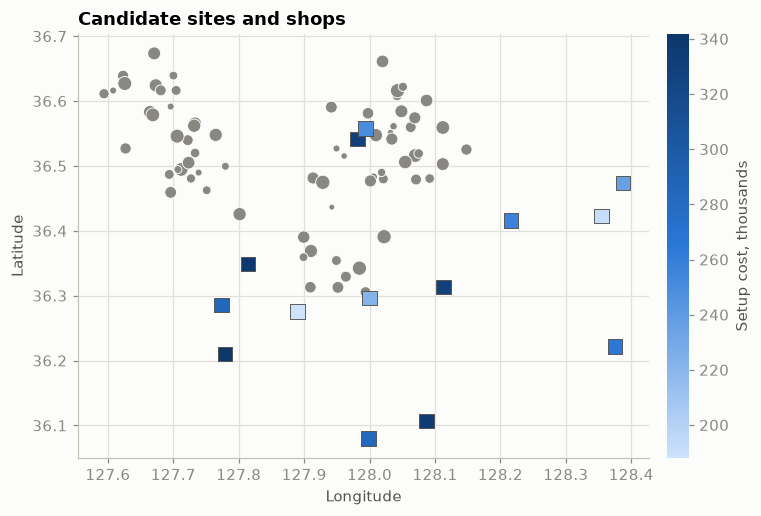

In [3]:
blues = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#2a78d6", "#0d366b"])

fig, ax = plt.subplots(figsize=(7.2, 5))
ax.scatter([s["location"][1] for s in shops], [s["location"][0] for s in shops],
           s=[3 * s["demand"] for s in shops], color=MUTED, edgecolor="#fcfcfb", linewidth=0.6, zorder=2)
squares = ax.scatter([s["location"][1] for s in sites], [s["location"][0] for s in sites], marker="s", s=90,
                     c=[s["setup_cost"] / 1000 for s in sites], cmap=blues, edgecolor=INK, linewidth=0.6, zorder=3)
colorbar = fig.colorbar(squares, ax=ax, label="Setup cost, thousands", fraction=0.04, pad=0.03)
colorbar.outline.set_visible(False)
ax.set(title="Candidate sites and shops", xlabel="Longitude", ylabel="Latitude")
ax.grid(True)
plt.show()

## 2. Solve it

`fl.solve` works in place: each consumer gets a facility index, and the score is written onto `problem`. The
score has two levels, compared in order:

- **hard**: minus the demand above capacity, summed over the sites in use. `0` means the network is feasible.
- **soft**: minus (2 × the setup cost of the sites in use + 6 × the total shop-to-depot metres)

A site that serves nobody costs nothing, so "opening a site" means assigning at least one shop to it.

In [4]:
score = fl.solve(problem, time_limit_seconds=4, random_seed=42)

assignment = problem.assignment()
open_sites = sorted(set(assignment))

print("feasible:", score.is_feasible())
print("score   :", score.hard, "/", score.soft)
print("open    :", [problem.facilities[f].id for f in open_sites])
print(f"setup   : {problem.total_cost():,}")
print(f"distance: {problem.total_distance_meters() / 1000:,.0f} km, "
      f"{problem.total_distance_meters() / 1000 / problem.consumer_count():.1f} km per shop")

feasible: True
score   : 0 / -10014470.0
open    : ['Site 1', 'Site 7', 'Site 10', 'Site 11', 'Site 12']
setup   : 1,424,920
distance: 1,194 km, 17.1 km per shop


### The network on a map

Each shop is tied to its depot. Open sites are filled squares, labelled and colored by site. Closed sites are
hollow. The colors stay with these sites for the rest of the notebook, and a site that opens only in a later
experiment is drawn gray.

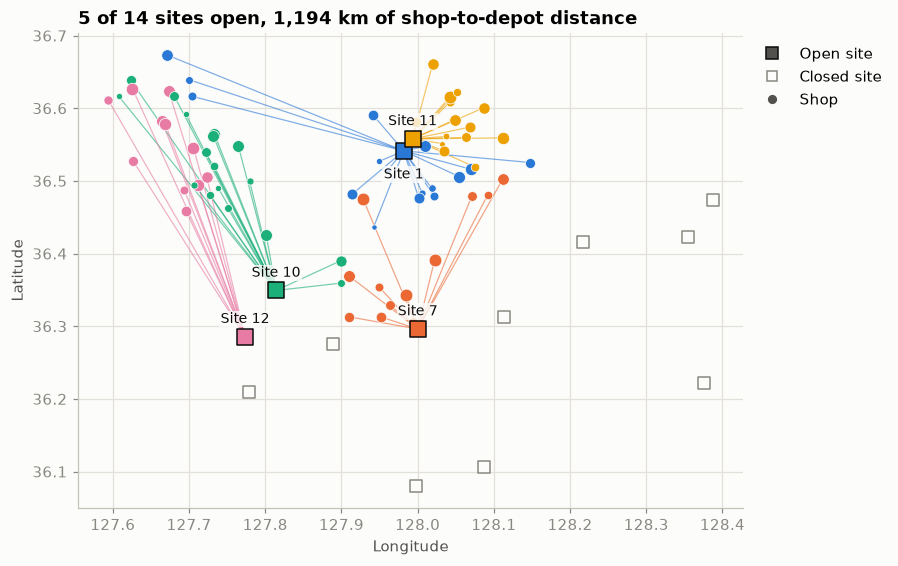

In [5]:
SITE_COLOR = {site: COLORS[slot] for slot, site in enumerate(open_sites)}
OTHER = MUTED


def draw_network(ax, problem, label_sites=True):
    assignment = problem.assignment()
    for consumer, site in zip(problem.consumers, assignment):
        color = SITE_COLOR.get(site, OTHER)
        depot = problem.facilities[site].location
        ax.plot([consumer.location.longitude, depot.longitude], [consumer.location.latitude, depot.latitude],
                color=color, linewidth=0.8, alpha=0.6, zorder=1)
        ax.scatter(consumer.location.longitude, consumer.location.latitude, s=2.4 * consumer.demand, color=color,
                   edgecolor="#fcfcfb", linewidth=0.5, zorder=2)
    used = set(assignment)
    for index, facility in enumerate(problem.facilities):
        point = (facility.location.longitude, facility.location.latitude)
        crowded = any(
            0 < problem.facilities[other].location.latitude - point[1] < 0.06
            and abs(problem.facilities[other].location.longitude - point[0]) < 0.12
            for other in used
        )
        if index in used:
            ax.scatter(*point, marker="s", s=110, color=SITE_COLOR.get(index, OTHER), edgecolor="#0b0b0b",
                       linewidth=1, zorder=4)
            if label_sites:
                ax.annotate(facility.id, point, xytext=(0, -18 if crowded else 9), textcoords="offset points",
                            ha="center", color="#0b0b0b", fontsize=9, zorder=5,
                            bbox=dict(facecolor="#fcfcfb", edgecolor="none", alpha=0.8, pad=0.8))
        else:
            ax.scatter(*point, marker="s", s=60, facecolor="#fcfcfb", edgecolor=MUTED, linewidth=1, zorder=3)
    ax.set(xlabel="Longitude", ylabel="Latitude")
    ax.grid(True)


NETWORK_LEGEND = [
    Line2D([], [], linestyle="", marker="s", markerfacecolor=INK, markeredgecolor="#0b0b0b", markersize=8,
           label="Open site"),
    Line2D([], [], linestyle="", marker="s", markerfacecolor="#fcfcfb", markeredgecolor=MUTED, markersize=7,
           label="Closed site"),
    Line2D([], [], linestyle="", marker="o", color=INK, markersize=5, label="Shop"),
]

fig, ax = plt.subplots(figsize=(7.8, 5.6))
draw_network(ax, problem)
ax.set_title(f"{len(open_sites)} of {problem.facility_count()} sites open, "
             f"{problem.total_distance_meters() / 1000:,.0f} km of shop-to-depot distance")
ax.legend(handles=NETWORK_LEGEND, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 3. Check the result yourself

`assignment()` is the whole answer, so everything can be recomputed from it with no solver code: every shop
is served, no depot is over capacity, and the soft score equals the setup and distance formula.

`problem.consumers` and `problem.facilities` return copies. Reading them is fine, and `set_assignment` is the
way to write a whole assignment back.

every shop has a depot: True
sites over capacity   : []
soft score recomputed : -10,014,470
soft score from solver: -10,014,470


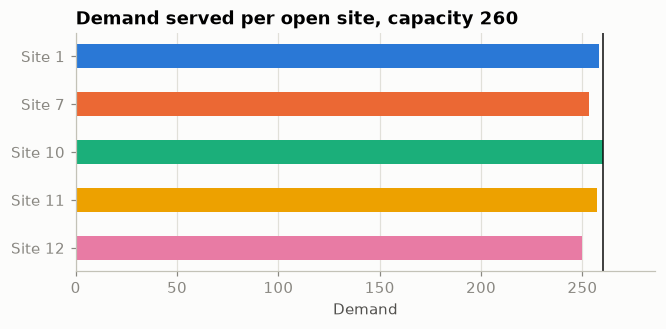

In [6]:
def metres(a, b):
    return math.ceil(math.sqrt((a.latitude - b.latitude) ** 2 + (a.longitude - b.longitude) ** 2) * 111_000)


loads = {site: 0 for site in open_sites}
total_metres = 0
for consumer, site in zip(problem.consumers, assignment):
    loads[site] += consumer.demand
    total_metres += metres(consumer.location, problem.facilities[site].location)
setup = sum(problem.facilities[site].setup_cost for site in open_sites)
recomputed = -(2 * setup + 6 * total_metres)

print("every shop has a depot:", all(site >= 0 for site in assignment))
print("sites over capacity   :", [problem.facilities[s].id for s, load in loads.items() if load > CAPACITY])
print(f"soft score recomputed : {recomputed:,}")
print(f"soft score from solver: {problem.score.soft:,.0f}")

fig, ax = plt.subplots(figsize=(6.8, 2.8))
names = [problem.facilities[site].id for site in open_sites]
ax.barh(names, [loads[site] for site in open_sites], height=0.5, color=[SITE_COLOR[site] for site in open_sites])
ax.axvline(CAPACITY, color="#0b0b0b", linewidth=1)
ax.invert_yaxis()
ax.set(title=f"Demand served per open site, capacity {CAPACITY}", xlabel="Demand", xlim=(0, CAPACITY * 1.1))
ax.grid(True, axis="x")
plt.show()

## 4. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and `solve` takes the list you
want through `constraints=`. Only listed constraints are scored.

In [7]:
for name in fl.list_constraints():
    print(name)

facility_capacity
facility_setup_cost
distance_from_facility


The default weights trade 6 per metre against 2 per unit of setup cost. If a metre costs more than that, say
because deliveries are perishable or because fuel prices rise, then more depots pay for themselves. Keep the
capacity and setup rules, and raise `distance_from_facility` to 60.

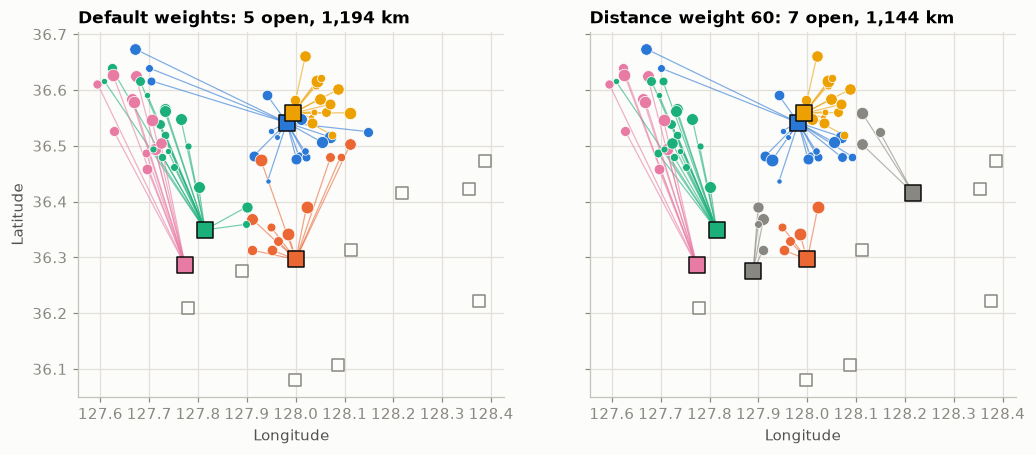

default: 5 sites, setup 1,424,920, 1,194 km
weight 60: 7 sites, setup 1,870,705, 1,144 km


In [8]:
HIGH_WEIGHT = 60
closer = make_problem()
fl.solve(closer, time_limit_seconds=4, random_seed=42,
         constraints=[rules.capacity, rules.setup_cost, rules.DistanceFromFacility(weight=HIGH_WEIGHT)])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharex=True, sharey=True)
for ax, result, title in ((axes[0], problem, "Default weights"), (axes[1], closer, f"Distance weight {HIGH_WEIGHT}")):
    draw_network(ax, result, label_sites=False)
    ax.set_title(f"{title}: {result.used_facility_count()} open, {result.total_distance_meters() / 1000:,.0f} km",
                 fontsize=11)
axes[1].set_ylabel("")
plt.show()

for label, result in (("default", problem), (f"weight {HIGH_WEIGHT}", closer)):
    print(f"{label}: {result.used_facility_count()} sites, setup {result.total_cost():,}, "
          f"{result.total_distance_meters() / 1000:,.0f} km")

Scores from two weights are not comparable, so compare the sites, setup and kilometres. Gray marks a site that
did not open under the default weights.

## 5. What capacity is worth

Depots cost money to expand, so what does capacity buy? This solves the same network at different capacities
and splits each bill at the default weights: 2 × setup cost, and 6 × metres. The row at the default capacity is
the solution from section 2.

When capacity falls, more sites must open. The solver stops on a clock, so each row is the best found in the
time limit.

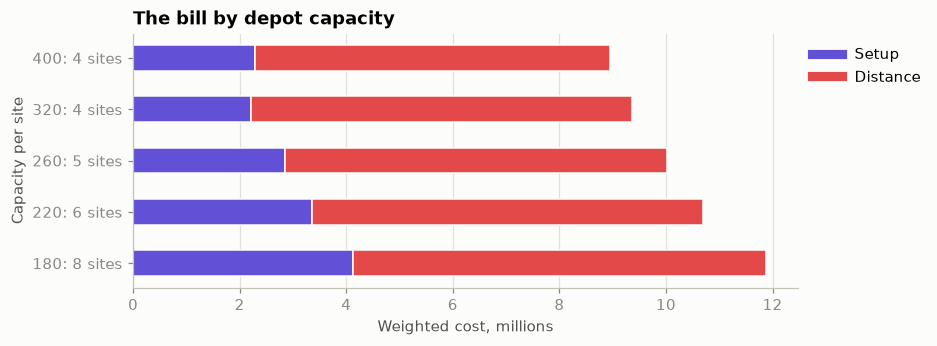

capacity 400: hard 0, 4 sites, weighted bill 8.96 million
capacity 320: hard 0, 4 sites, weighted bill 9.37 million
capacity 260: hard 0, 5 sites, weighted bill 10.01 million
capacity 220: hard 0, 6 sites, weighted bill 10.70 million
capacity 180: hard 0, 8 sites, weighted bill 11.88 million


In [9]:
SETUP_COLOR, DISTANCE_COLOR = COLORS[6], COLORS[7]
CAPACITIES = [400, 320, CAPACITY, 220, 180]


def bill(result):
    setup_part = result.setup_cost_weight * result.total_cost()
    return setup_part, result.distance_from_facility_weight * result.total_distance_meters()


results = {CAPACITY: problem}
for capacity in CAPACITIES:
    if capacity != CAPACITY:
        results[capacity] = make_problem(capacity)
        fl.solve(results[capacity], time_limit_seconds=2, random_seed=42)

fig, ax = plt.subplots(figsize=(7.8, 3))
for row, capacity in enumerate(CAPACITIES):
    setup_part, distance_part = bill(results[capacity])
    ax.barh(row, setup_part / 1e6, height=0.5, color=SETUP_COLOR, edgecolor="#fcfcfb", linewidth=1)
    ax.barh(row, distance_part / 1e6, left=setup_part / 1e6, height=0.5, color=DISTANCE_COLOR,
            edgecolor="#fcfcfb", linewidth=1)
ax.set_yticks(range(len(CAPACITIES)),
              [f"{capacity}: {results[capacity].used_facility_count()} sites" for capacity in CAPACITIES])
ax.invert_yaxis()
ax.set(title="The bill by depot capacity", xlabel="Weighted cost, millions", ylabel="Capacity per site")
ax.grid(True, axis="x")
ax.legend(handles=[Line2D([], [], color=SETUP_COLOR, linewidth=6, label="Setup"),
                   Line2D([], [], color=DISTANCE_COLOR, linewidth=6, label="Distance")],
          loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for capacity in CAPACITIES:
    result = results[capacity]
    print(f"capacity {capacity}: hard {result.score.hard}, {result.used_facility_count()} sites, "
          f"weighted bill {sum(bill(result)) / 1e6:.2f} million")

## 6. Keep working from an existing network

### New shops

Eight new shops sign up. The sites that are open should stay the starting point, so the search begins from the
current network rather than from nothing.

`with_initial_solution` works on the pydantic models in `optimaru.facility_location.models`. `from_core` turns a
solved problem into a model, and `to_core` turns it back. Consumers are matched by id, and a consumer the solution
does not mention is placed by the construction heuristic. Facilities must stay the same and in the same
order, because `facility` is a position in that list.

The restart uses a new `random_seed`, for the reason in the next section.

new shops without a depot before the restart: 8
score: 0 / -11115572.0
total demand 1438, capacity of the old open sites 1300
open: ['Site 1', 'Site 7', 'Site 10', 'Site 11', 'Site 12', 'Site 13']
existing shops that kept their depot: 54 of 70


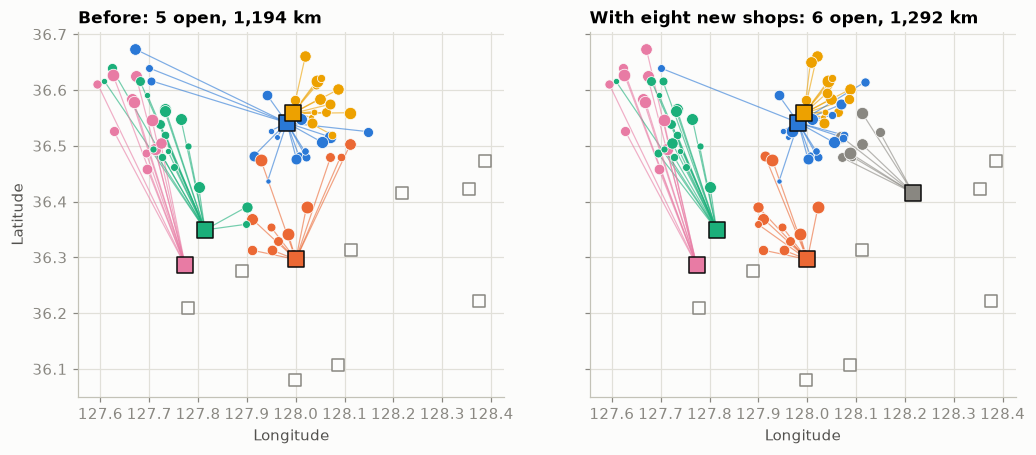

In [10]:
solved = FacilityLocationProblemModel.from_core(problem)

new_rng = np.random.default_rng(21)
larger = solved.model_copy(deep=True)
for i in range(8):
    latitude, longitude = towns[0] + new_rng.normal(0, 0.05, size=2)
    larger.consumers.append(ConsumerModel(
        id=f"New shop {i + 1}", location=LocationModel(latitude=latitude, longitude=longitude),
        demand=int(new_rng.integers(10, 30)),
    ))

grown = fl.with_initial_solution(larger, solved).to_core()
print("new shops without a depot before the restart:", sum(site < 0 for site in grown.assignment()))

fl.solve(grown, time_limit_seconds=3, random_seed=43)

kept = sum(a == b for a, b in zip(assignment, grown.assignment()))
new_demand = sum(c.demand for c in grown.consumers)
print("score:", grown.score.hard, "/", grown.score.soft)
print(f"total demand {new_demand}, capacity of the old open sites {len(open_sites) * CAPACITY}")
print("open:", [grown.facilities[f].id for f in sorted(set(grown.assignment()))])
print(f"existing shops that kept their depot: {kept} of {len(assignment)}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharex=True, sharey=True)
for ax, result, title in ((axes[0], problem, "Before"), (axes[1], grown, "With eight new shops")):
    draw_network(ax, result, label_sites=False)
    ax.set_title(f"{title}: {result.used_facility_count()} open, {result.total_distance_meters() / 1000:,.0f} km",
                 fontsize=11)
axes[1].set_ylabel("")
plt.show()

### More search, in rounds

`with_initial_solution` also lets you spend more time in rounds that each continue from the last answer. These
start from a network with no search in it: `time_limit_seconds=0` runs construction only.

**Give each round its own `random_seed`.** The same start with the same seed repeats the same search, so that
round has nothing new to find. A same-seed run can still improve for a while, because each better answer is a new
start. The first round that finds nothing ends it, because every later round repeats that one.

A flat line needs checking. A single solve can also stop improving well before its time limit, and more time does
not always free it, because closing a site means moving all of its shops at once. So the black line is the best
of several independent solves with different seeds. A run that stays above it is stuck. Try other seeds, from
scratch as well as from this answer, before raising the time limit.

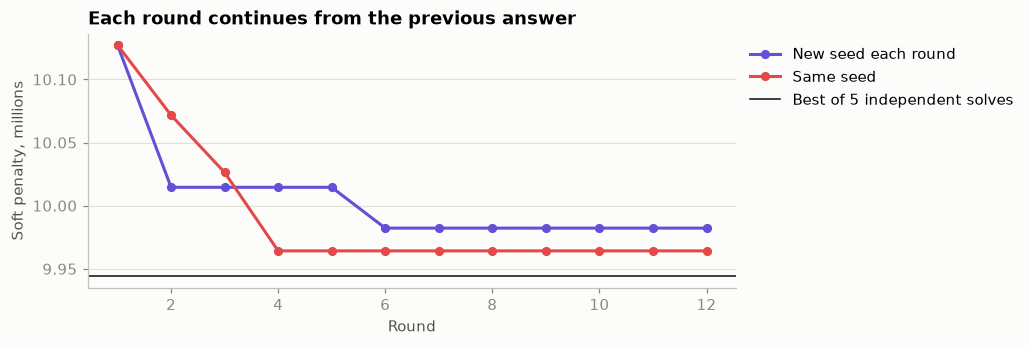

construction only: 17.317 million
after 12 rounds: new seed 9.982, same seed 9.964
independent 1 s solves by seed: [10.003, 10.014, 10.314, 9.993, 9.944]


In [11]:
ROUNDS = 12
ROUND_SECONDS = 0.05
SEEDS = [1, 2, 3, 4, 5]

base_model = FacilityLocationProblemModel.from_core(make_problem())


def solve_model(model, seconds, seed):
    core = model.to_core()
    fl.solve(core, time_limit_seconds=seconds, random_seed=seed)
    return FacilityLocationProblemModel.from_core(core)


def search_in_rounds(start, change_seed):
    history, current = [], start
    for round_number in range(ROUNDS):
        seed = 100 + round_number if change_seed else 100
        current = solve_model(fl.with_initial_solution(base_model, current), ROUND_SECONDS, seed)
        history.append(-current.score_soft / 1e6)
    return history


constructed = solve_model(base_model, 0, 42)
new_seed = search_in_rounds(constructed, change_seed=True)
same_seed = search_in_rounds(constructed, change_seed=False)

independent = [-solve_model(base_model, 1, seed).score_soft / 1e6 for seed in SEEDS]

fig, ax = plt.subplots(figsize=(7.6, 3))
rounds = range(1, ROUNDS + 1)
ax.plot(rounds, new_seed, color=COLORS[6], linewidth=2, marker="o", markersize=5, label="New seed each round")
ax.plot(rounds, same_seed, color=COLORS[7], linewidth=2, marker="o", markersize=5, label="Same seed")
ax.axhline(min(independent), color="#0b0b0b", linewidth=1, label=f"Best of {len(SEEDS)} independent solves")
ax.set(title="Each round continues from the previous answer", xlabel="Round", ylabel="Soft penalty, millions")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print(f"construction only: {-constructed.score_soft / 1e6:.3f} million")
print(f"after {ROUNDS} rounds: new seed {new_seed[-1]:.3f}, same seed {same_seed[-1]:.3f}")
print("independent 1 s solves by seed:", [round(value, 3) for value in independent])

## Next steps

- `SolverConfig` holds the search options, such as `close_facility_moves`, which empties a whole site in one step,
  and `parallel_solver_count` for independent parallel starts.
- `use-cases/facility-location/README.md` covers the data model, starting from a solution, and how to add your own
  moves and constraints in C++.
- For the routes that would run from these depots, see `vehicle-routing.ipynb`.